In [ ]:
from google.colab import files
video = files.updload()

# **Parámetros usuario**

**segundo_a_ver**: es el segundo a analizar en el recorte manual y estructura fija. Esta fijo en 25s pero puede ser modificado si deseas analizar otro segundo más crítico. Recomendación: que sea un frame donde la estructura fija se pueda ver bien (no en momentos de zoom o movimiento de cámara).

**Elección frame de referencia**

1. Correr la celda. Va a aparecer el framde del video (segundo 25) con 4 controles deslizantes: X inicio, Y inicio, Ancho, Alto
2. Mover los sliders hasta que el recángulo verde quede así:


*   La Aplysia completa adentro del cuadrado
*   Recomendación: revisar el vídeo antes de seleccionar el ROI. En caso de que se acerque al vidrio aumentar el Alto.

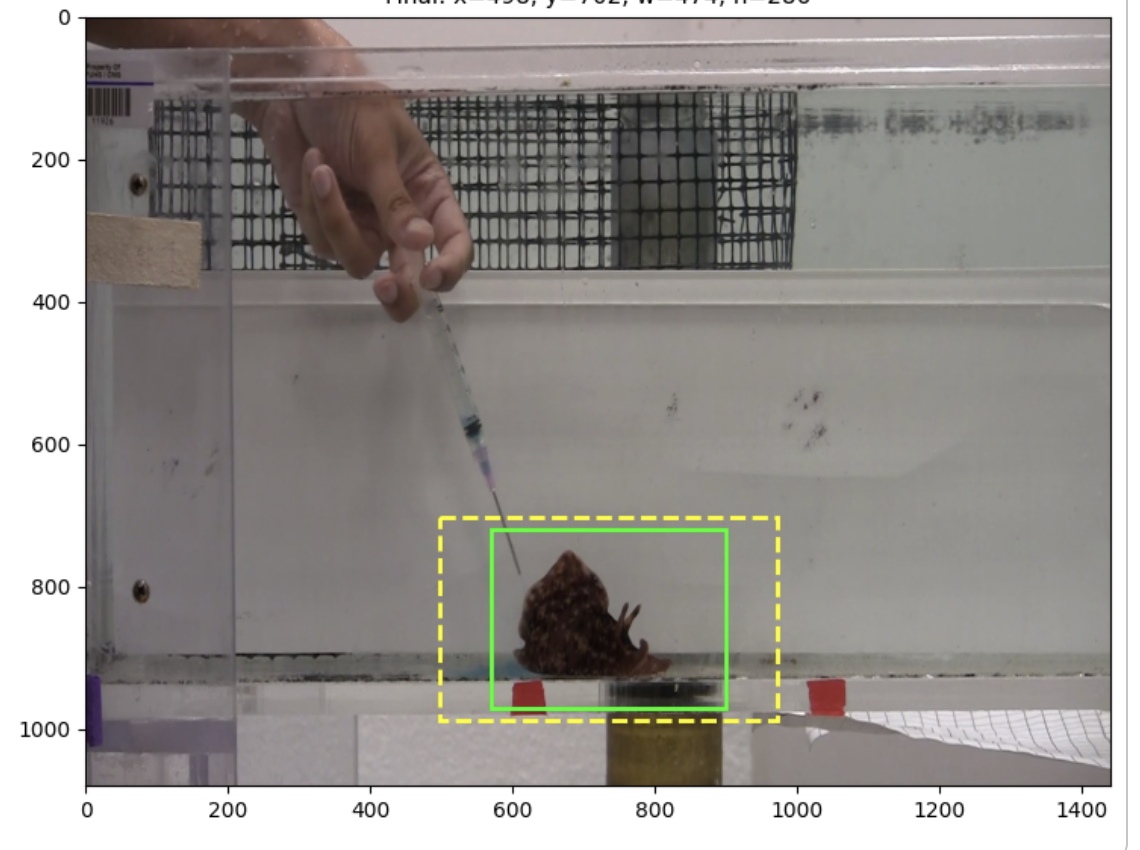

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display

nombre_video = list(video.keys())[0]
cap = cv2.VideoCapture(nombre_video)
cap.set(cv2.CAP_PROP_POS_MSEC, 10000)
ret, frame_roi = cap.read()
cap.release()

frame_rgb = cv2.cvtColor(frame_roi, cv2.COLOR_BGR2RGB)
alto, ancho = frame_rgb.shape[:2]

MARGEN_Y_PX = 18
MARGEN_X_PORCENTAJE = 0.22

roi_coords = {"x":0, "y":0, "w":0, "h":0}
roi_coords_final = {"x":0, "y":0, "w":0, "h":0}

sx = widgets.IntSlider(min=0, max=ancho-1, value=200, description='X inicio')
sy = widgets.IntSlider(min=0, max=alto-1, value=200, description='Y inicio')
sw = widgets.IntSlider(min=10, max=ancho, value=300, description='Ancho')
sh = widgets.IntSlider(min=10, max=alto, value=150, description='Alto')

out = widgets.Output()

def actualizar(x, y, w, h):
  roi_coords["x"]= x
  roi_coords["y"]= y
  roi_coords["w"]= w
  roi_coords["h"]= h

  margen_x = int(w * MARGEN_X_PORCENTAJE)
  x_final = max(0, x - margen_x)
  w_final = min(ancho, x + w + margen_x) - x_final
  y_final = max(0, y - MARGEN_Y_PX)
  h_final = min(alto, y + h + MARGEN_Y_PX) - y_final

  roi_coords_final["x"]= x_final
  roi_coords_final["y"]= y_final
  roi_coords_final["w"]= w_final
  roi_coords_final["h"]= h_final

  with out:
    out.clear_output(wait=True)
    fig, ax = plt.subplots(figsize = (13, 6))
    ax.imshow(frame_rgb)

    rect = patches.Rectangle((x,y),w,h,linewidth=2, edgecolor="lime", facecolor="none")
    ax.add_patch(rect)

    rect_final = patches.Rectangle((x_final, y_final), w_final, h_final,
                                   linewidth=2, edgecolor="yellow",linestyle='--', facecolor="none")
    ax.add_patch(rect_final)

    ax.set_title(f"Verde = Ajuste manual | Amarillo punteado = ROI final (con margen)\n"
                  f"Final: x = {x_final}, y = {y_final}, w = {w_final}, h = {h_final}", fontsize=11)
    plt.tight_layout()
    plt.show()

ui.widgets.VBox([sx, sy, sw, sh])
widgets.interactive_output(actualizar, {"x": sx, "y": sy, "w": sw, "h": sh})
display(ui, out)
actualizar(sx.value, sy.value, sw.value, sh.value)

# Recorte manual

IMPORTANTE: Uso SÓLO en casos con 1 error que afecta el cálculo



In [ ]:
import cv2, base64
from google.colab import output
from IPython.display import display, HTML

nombre_video = list(video.keys())[0]
SEGUNDO_A_VER = 25
cap = cv2.VideoCapture(nombre_video)
fps = cap.get(cv2.CAP_PROP_FPS)
cap.set(cv2.CAP_PROP_POS_FRAMES, int(SEGUNDO_A_VER * fps))
ret, frame = cap.read()
cap.release()

_, buf = cv2.imencode('.png', frame)
b64 = base64.b64encode(buf).decode()

ZONA_MANUAL_RESULTADO = {}

def _guardar_zona(x1, y1, x2, y2):
  global ZONA_MANUAL_RESULTADO
  x, y = int(min(x1, x2)), int(min(y1, y2))
  w, h = int(abs(x2 - x1)), int(abs(y2 - y1))
  ZONA_MANUAL_RESULTADO = {"x": x, "y": y, "w": w, "h": h, "t_s": float{SEGUNDO_A_VER}, "video": nombre_video}
  print(f"Zona guardada (coordenadas reales de la imagen): x={x}, y={y}, w={w}, h={h} | en el segundo {SEGUNDO_A_VER} de {nombre_video}")

output.register_callback('notebook.guardar_zona', _guardar_zona)

html = f'''
<div>
  <canvas id="canvas_zona" style="cursor:crosshair;border:1px solid #333;max-width:100%;height:auto;"></canvas>
  <p>Hacer click y arrastrar sobre la imagen para marcar el rectángulo. Soltar el mouse para confirmar.</p>
</div>
<script>
var img = new Image();
img.onload = function() {{
  var canvas = document.getElementById('canvas_zona');
  canvas.width = img.width;
  canvas.height = img.height;
  var ctx = canvas.getContext('2d');
  ctx.drawImage(img, 0, 0);
  var startX, startY, drawing = false;

  function coordsReales(e) {{
    var r = canvas.getBoundingClientRect();
    var escalaX = canvas.width / r.width;
    var escalaY = canvas.height / r.height;
    return [(e.clientX - r.left) * escalaX, (e.clientY - r.top) * escalaY];
  }}

  canvas.onmousedown = function(e) {{
    var c = coordsReales(e);
    startX = c[0]; startY = c[1];
    drawing = true;
  }};
  canvas.onmousemove = function(e) {{
    if (!drawing) return;
    var c = coordsReales(e);
    var curX = c[0], curY = c[1];
    ctx.drawImage(img, 0, 0);
    ctx.strokeStyle = 'red';
    ctx.lineWidth = 2;
    ctx.strokeRect(startX, startY, curX - startX, curY - startY);
  }};
  canvas.onmouseup = function(e) {{
    drawing = false;
    var c = coordsReales(e);
    google.colab.kernel.invokeFunction('notebook.guardar_zona', [startX, startY, c[0], c[1]], {{}});
  }};
}};
img.src = "data:image/png;base64,{b64}";
</script>
'''
display(HTML(html))

# Parte automática

Importante:
1. Hay que correr el código en el orden establecido
2. Para usar el caso de emergencia utiliza como referencia la imagen del paso de estructuras fijas. Si ves que la estructura fija no queda bien definida utiliza el botón de recorte manual para eliminar cualquier problema en el video.


In [ ]:
#ESTRUCTURAS FIJAS
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Valores fijos
kernel_gauss = 7 #suavizado gaussiano 7x7px para eliminar el ruido antes de analizar c/frame
kernel_var = 25 #ventana 25x25px donde se mide la textura
v_max_textura = 70 #píxel cuenta como oscuro si su brillo V es menor que 70 (entre 0 a 255)
factor_umbral = 1.05 #umbral de textura calculado con Otsu (5% más exigente)
n_muestras = 60 #cantidad de frames analizados repartidos
kernel_relleno = 15 #cierre morfológico de 15px (rellena huecos dentro de la estructura)
area_min_estructura = 150 #manchas de menos de 150px se eliminan = ruido
piso_umbral_estructura = 0.85 #sobre el piso: 1 píxel es estructura SI sale oscuro en al menos 85% de los frames
umbral_debajo_piso = 0.6 #bajo el piso: 1 píxel es estructura SI al menos sale oscuro en el 60% de los frames
margen_inicio = 0.01 #se salta el primer 1% del video al elegir los frames
margen_fin = 0.06 #se salta el último 6% del video al elegir los frames

#Cámara
#Se alinea cada frame con un frame de referencia por movimiento de camára o zoom
#Con esto se busca calcular cuanto se mueve la imagen y se corrige
#Mejora la máscara de estructura fija

alinear_camara = True #True = cada frame se alinea con el de referencia antes de contar
segundo_referencia = 25.0 #seg que se usa como referencia (cambia si se usa el recorte manual)
ali_escala = 0.5 #frames se achican a la mitad para buscar puntos
ali_n_puntos = 3000 #cantidad de puntos del fondo se buscan en cada frame
ali_min_inliers = 40 #mín de puntos que tienen que calzar entre el frame y referencia = con menos se descarta
ali_margen_roi_px = 30 #alrededor del animal (roi+30px) no se buscan puntos
min_frames_validos = 20 #1 píxel se evalúa si se vio en al menos 20 frames alineados

#Piso
#En base de donde está el animal encuentra el piso para separar el tubo del animal
usar_piso = True #se busca la línea del piso
sombra_min = 0.03 #sombra del animal = píxeles oscuros en + del 3% de los frames
sombra_min_alto_px = 40 #columna de imagen debe tener al menos 40px para buscar sombra
sombra_min_columnas = 50 #se necesitan al menos 50 columnas con la restricción anterior
margen_piso_px = 8 #margen de error
relleno_desde_piso_px = 4 #en columnas con estructura bajo el piso se rellena desde 4px bajo la línea hasta estructura
relleno_lados_px = 4 #relleno se ensancha 4px hacia cada lado para evitar bordes sueltos
frac_franja_pie = 0.40 #franja del pie que no es estructura: desde el piso hacia arriba 40% altura promedio del animal

#Gabor
#Parámetros de Gabor: 4 filtros de textura
GABOR_PARAM = [
    {"freq": 1/12, "theta": 0}, #frec 12px+0º
    {"freq": 1/12, "theta": np.pi/4}, #frec 12px + 45º
    {"freq": 1/16, "theta": 0}, #frec 16px +0º
    {"freq": 1/16, "theta": np.pi/4}, #frec 16px + 45º
]

#Se arma GABOR con OpenCV:
#(31,31) tamaño del filto en px
#4.0 sigma: que tan grande es la zona que observa alrededor de cada píxel
#p["theta"] inclinación
# 1.0/p["freq"] largo de onda: cada cuántos px se repite
#0.5 gamma: filtro es alargado (mitad ancho que alto)
#0 psi: desfase de la onda
#ktype=cv2.CV_32F filtro se guarda con decimales

kernels = [cv2.getGaborKernel((31,31), 4.0, p["theta"], 1.0/p["freq"], 0.5, 0, ktype=cv2.CV_32F)
            for p in GABOR_PARAM]

#Medición textura píxel
#Calcula variación del brillo en la ventana que lo rodea (25x25px)
def varianza_local(gris, kernel_size):
  f = gris.astype(np.float32) #pasa la imagen a decimales
  return np.clip(cv2.blur(f**2, (kernel_size, kernel_size)) - cv2.blur(f,(kernel_size, kernel_size))**2, 0, None)
#cv2.blur promedio en la ventana alrededor de cada píxel
#blur(f**2) promedio de los brillos al cuadrado
#blur(f)**2 cuadrado del brillo promedio
#resta es la varianza local: Var = E[x^2]-(E[x])^2

#Separa píxeles en 2 grupos con umbral automático
#Píxeles + oscuros = animal
def binarizar_animal_oscuro(gris, combinado, factor_umbral=factor_umbral):
  t_otsu,_ = cv2.threshold(combinado, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU) #umbral automático con Otsu: busca el valor que separa mejor los píxeles en 2 grupos
  t_ajustado = float(np.clip(t_otsu * factor_umbral,0,255)) #hace al umbral un 5% más exigente y asegura que esté entre 0 y 255
  _, mask_a = cv2.threshold(combinado, t_ajustado,255, cv2.THRESH_BINARY) #A = píxeles x encima del umbral
  _, mask_b = cv2.threshold(combinado, t_ajustado,255, cv2.THRESH_BINARY_INV) #B = píxeles x debajo del umbral
  brillo_a = gris[mask_a == 255].mean() if np.any(mask_a == 255) else 255 #brillo promedio en la imagen en gris de cada grupo si está vacío = 255 (blanco)
  brillo_b = gris[mask_b == 255].mean() if np.any(mask_b == 255) else 255
  return mask_a if brillo_a < brillo_b else mask_b #el animal es el grupo más oscuro

#Mezcla las dos definciones anteriores
#toma un frame y devuelve una máscara con píxeles que son oscuros y con textura
#lo hace en 5 pasos
def mascara_oscura(frame):
  #Paso 1 preparación de imagen
  v_original = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)[:,:,2] #canal V (brillo) del frame original para el filtro de oscuridad del final
  suave = cv2.GaussianBlur(frame, (kernel_gauss, kernel_gauss),0) #suavizado 7x7px para sacar ruido
  gris = cv2.cvtColor(suave, cv2.COLOR_BGR2GRAY) #escala de grises
  gris = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8)).apply(gris) #CLAHE: aumenta el contraste x zonas (8x8), con límite 3.0 (no exagerar ruido y resalta textura), aunque iluminación no es pareja
  gris_f = gris.astype(np.float32) #a decimales para filtrar
  #paso 2 textura con filtros de gabor
  suma = np.zeros_like(gris_f) #imagen en 0 donde se van sumando las respuestas
  for k in kernels: #para cada 1 de los 4 filtros de gabor
    suma += np.abs(cv2.filter2D(gris_f, cv2.CV_32F, k)) #se pasa el filtro x la imagen y se suma la respuesta en valor absoluto
  gabor_inv = cv2.bitwise_not(cv2.normalize(suma/len(kernels), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)) #promedio de los 4 filtros escalado a 0-255 e invertido (donde responde fuerte es oscuro y lo otro claro)
  # paso 2 textura con varianza local
  var_norm = cv2.normalize(varianza_local(gris, kernel_var), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8) #varianza en ventanas de 25x25px escalada a 0-255
  #paso 3 combinar
  combinado = cv2.addWeighted(gabor_inv,0.6, var_norm, 0.4, 0) #60% gabor invertido + 40% varianza
  #paso 4 separa animal + fondo
  mask = binarizar_animal_oscuro(gris, combinado) #umbral otsu x1.05 y se queda con los + oscuro
  #paso 5 se queda solo con lo oscuro
  mask_oscuro = (v_original < v_max_textura).astype(np.uint8)*255 #píxeles con brillo V < 70 en el frame original
  return cv2.bitwise_and(mask, mask_oscuro) #resultado = tiene textura de animal Y es oscuro

#Limpia máscara
#rellena huecos chicos y bota manchas pequeñas
def limpiar_mascara(mask_previa):
  #kernel relleno con elipse 15x15px: agranda la imagen, rellena huecos, achica imagen
  mask_cerrada = cv2.morphologyEx(mask_previa, cv2.MORPH_CLOSE,
                                  cv2.cv2.getStructuringElement(cv2.cv2.MORPH_ELLIPSE,(kernel_relleno, kernel_relleno)))
  #separa la máscara en manchas (grupo de píxeles blancos conectados contando diagonales)
  #n_labels = cantidad manchas que hay (+1 x el fondo) | labels = nº de mancha de c/pixel | stats = dato de c/mancha
  n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_cerrada, connectivity=8)
  salida = np.zeros_like(mask_cerrada) #máscara vacía donde se copian solo las manchas que sirven
  for i in range(1, n_labels): #recorre c/mancha se parte en 1 porque 0 es el fondo
    if stats[i, cv2.CC_STAT_AREA] > area_min_estructura: #si la mancha tiene + de 150px
      salida[labels == i] = 255 #se copia en blanco a la salida (chicas se descartan)
  return salida


nombre_video = list(video.keys())[0] #nombre del video
nombre_base_video = nombre_video.rsplit(".",1)[0] #mismo nombre del video sin extensión para nombrar archivos de salida

#Recorte manual
#revisa si existe el recorte manual y el segundo en que se hizo
ZONA_MANUAL_RESULTADO = globals().get("ZONA_MANUAL_RESULTADO", {}) #busca el recorte si no existe queda vacío
ZONAS_MANUALES = [] #lista de recortes
ZONA_MANUAL_T_S = 0.0 #segundo del video en que se hizo el recorte
if ZONA_MANUAL_RESULTADO: #si hay un recorte guardado
  video_zona = ZONA_MANUAL_RESULTADO.get("video") #se revisa en que vídeo es
  if video_zona is not None and video_zona != nombre_video: #si es otro video NO se usa
      print(f"IMPORTANTE: hay un recorte manual guardado pero es de OTRO video ({video_zona}) por lo tanto NO se usa."
           f"Si este video necesita recorte, vuelve a correr la celda de dibujar.")
  else: #si esta bien el video se guardan las coordenadas
      ZONAS_MANUALES = [(ZONA_MANUAL_RESULTADO["x"], ZONA_MANUAL_RESULTADO["y"], ZONA_MANUAL_RESULTADO["w"], ZONA_MANUAL_RESULTADO["h"])]
  if "t_s" in ZONA_MANUAL_RESULTADO: #si la celda de dibujar guardó el seg se usa ese seg
      ZONA_MANUAL_T_S = float(ZONA_MANUAL_RESULTADO["t_s"])
  else: #sino celda antigua se usa el segundo anterior o el de referencia
    ZONA_MANUAL_T_S = float(globals().get("SEGUNDO_A_VER", segundo_referencia))
    print(f"Aviso: el recorte se dibujó con la celda antigua (no guardó el segundo). Se asume el segundo {ZONA_MANUAL_T_S}.")

#Frame de referencia
#se usa para alinear la cámara + extracción de datos básicos
mascara_ref_t_s = ZONA_MANUAL_T_S if ZONAS_MANUALES else float(segundo_referencia) #si hay recorte manual se usa ese como seg de referencia sino el establecido
cap = cv2.VideoCapture(nombre_video) #abre el video
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) #cant total de frames
ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) #ancho c/frame px
alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) #alto c/frame px
fps = cap.get(cv2.CAP_PROP_FPS) #frames x segundo
if not fps or fps <= 0: #se asume 30 fps si es que no se extrae bien la info
  fps = 30.0
cap.release() #cierre video

#Alineamiento de cámara
#armado de máscara donde buscar los puntos + detector de puntos + comparador
roi_ali = globals().get("roi_coords_final", None) #roi manual
mascara_puntos = np.full((int(alto * ali_escala),int(ancho * ali_escala)), 255, np.uint8) #máscara del tamaño del frame a la mitad
if roi_ali and roi_ali.get("w"): #si hay roi definido se calcula el rectángulo del roi con el margen
  #evitar que esquinas queden fuera de la imagen
  x0= max(0, int((roi_ali["x"] - ali_margen_roi_px)* ali_escala)); y0 = max(0, int((roi_ali["y"] - ali_margen_roi_px)*ali_escala))
  x1 = int((roi_ali["x"] + roi_ali["w"] + ali_margen_roi_px) * ali_escala); y1 = int((roi_ali["y"] + roi_ali["h"] + ali_margen_roi_px) * ali_escala)
  mascara_puntos[y0:y1, x0:x1] = 0 #donde está el animal se pone en 0 = no se buscan puntos

orb = cv2.ORB_create(ali_n_puntos) #detector ORB: encuentra hasta 3000 puntos característicos y lo etiqueta/describe para reconocerlo en otro frame
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True) #empareka cada punto con el más parecido del otro frame
#norm_hamming es la forma de medir el parecido entre huellas ORB (cuenta bits ≠)
#crosscheck=true solo acepta un par si el punto A elige a B y B elige a A (disminuir errores)

#Ptos característicos
#toma un frame y devuelve los puntos con la etiqueta
def puntos(frame):
  g = cv2.resize(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (mascara_puntos.shape[1], mascara_puntos.shape[0])) #frames a gris y lo achica a tamaño mascara_puntos
  return orb.detectAndCompute(g, mascara_puntos) #devuelve lista con ptos con posición + matriz etiqueta

#Búsqueda frame de referencia
frame_ref = None #variable para guardar el frame
if alinear_camara: #sólo si se activa la alineación de cámara
  n_ref = int(round(mascara_ref_t_s * fps)) #pasa de seg ref a nº frame
  cap_ref = cv2.VideoCapture(nombre_video) #abre el video con lector aparte
  for _i in range(n_ref +1): #lee frames uno x uno desde el inicio hasta el frame ref
    ok_r, fr_r = cap_ref.read()
    if not ok_r: #si el video se acaba antes o falla lectura se detiene
      break
    frame_ref = fr_r #se queda con último frame leído
  cap_ref.release() #cierra lector
  if frame_ref is None: #si no se lee ningún frame se detectiva la alineación
    print("Aviso: no se pudo leer el frame de referencia, por lo tanto, se sigue SIN alinear.")
    alinear_camara = False
  else:
    k_ref, d_ref = puntos(frame_ref) #puntos k_ref y etiqueta d_ref para comparar después

#Cálculo de fracción de los frames que salieron oscuros
cap = cv2.VideoCapture(nombre_video) #abre el video
frame_inicio = int(total_frames * margen_inicio) #1er frame que se usa
frame_fin = int(total_frames * (1 - margen_fin)) #último frame que se usa
indices_muestra = np.linspace(frame_inicio, frame_fin, n_muestras, dtype=int) #60 frames repartidos entre límites
acumulador = np.zeros((alto, ancho), dtype=np.float32) #por píxel en cuántos frames salió oscuro (parte en 0)
vistos = np.zeros((alto, ancho), dtype=np.float32) #por píxel en cuántos frames se vió (parte en 0)
frames_leidos = frames_alineados = 0 #contador para aviso del final
unos = np.ones((alto, ancho), dtype=np.float32) #imgan llena de 1

for idx in indices_muestra: #para c/u de los 60 frames elegidos salta a ese frame
  cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
  ret, frame = cap.read()
  if not ret:
    continue #si no lo puede leer se lo salta
  frames_leidos += 1
  oscuro = (mascara_oscura(frame) > 0).astype(np.float32) #1 = píxel oscuro con textura 0=no
  if not alinear_camara: #sin alineación
    acumulador += oscuro; vistos += unos
    continue
  k, d = puntos(frame) #con alineación: calcular cuánto se movió la cámara respecto al frame de ref
  M = None #M transformación (mov e cámara); parte vacía
  if d is not None and d_ref is not None and len(k) >= 10: #solo si hay al menos 10 puntos para comparar
    pares = bf.match(d, d_ref) #empareja puntos con frame ref
    if len(pares) >= 15: #se necesitan al menos 15 pares para estimar movimiento
      p_frame = np.float32([k[x.queryIdx].pt for x in pares]) /ali_escala #posición de c/pto en este frame
      p_ref = np.float32([k_ref[x.trainIdx].pt for x in pares]) /ali_escala #posición pto pareja en frame de ref
      M, inl = cv2.estimateAffinePartial2D(p_frame, p_ref, method=cv2.RANSAC, ransacReprojThreshold=3) #estima mov (cuanto se corre + giro + zoom)+ RANSAC ignora los pares que no calzan (+3px de error); inl dice qué pares sí calzaron
      if M is not None and int(inl.sum()) < ali_min_inliers: #si calzaron menos de 40 pares = no confiable
        M = None #se descarta
  if M is None: #si no se pudo alinear este frame = se descarta
    continue
  frames_alineados += 1
  acumulador += cv2.warpAffine(oscuro, M, (ancho, alto), flags=cv2.INTER_NEAREST, borderValue=0) #mueve la máscara de oscuro a las coord de ref y las suma (c/píxel es siempre el mismo lugar del tanque)
  vistos += cv2.warpAffine(unos, M, (ancho, alto), flags=cv2.INTER_NEAREST, borderValue=0) #mueve la imagen de unos: bordes que quedaron fuera quedan en 0
cap.release()

min_vistos = min_frames_validos if alinear_camara else 1 #min de veces que se tiene que haber visto 1 píxel
frecuencia = np.where(vistos >= min_vistos, acumulador / np.maximum(vistos, 1), 0).astype(np.float32) #frecuencia x pixel = cant veces oscuro / cant veces visto (0 a 1) [si se ve menos de 20 veces = 0] / np.maximum evita dividir x 0
if alinear_camara and frames_alineados < min_frames_validos: #aviso si se alinearon pocos frames
  print(f"Importante: solo se pudieron alinear {frames_alineados} de {frames_leidos} frames; las estructuras automáticas pueden salir incompletas.")

frecuencia_u8 = (frecuencia * 255).astype(np.uint8) #pasa la frec 0-1 a 0-255 para otsu
t_otsu_frec, _ = cv2.threshold(frecuencia_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU) #umbral automático de otsu sobre frec
umbral_relativo = max(t_otsu_frec / 255.0, piso_umbral_estructura) #umbral sobre piso = el mayor entre otsu y 0.85

#Búsqueda línea del piso con sombra animal
y_piso = None #fila en px de la línea del piso none no encuentra
franja_pie_px = 0 #alto en px de la franja del pie que nunca es estructura
if usar_piso:
  sombra = ((frecuencia > sombra_min) & (frecuencia < umbral_debajo_piso)).astype(np.uint8) #px oscuros a rato: + del 3% de los frames y menos 60% no es estructura
  sombra = cv2.morphologyEx(sombra, cv2.MORPH_OPEN, np.ones((5,5), np.uint8).astype(bool)) #borra ruido
  y_desde = int(0.4 * alto) #piso busca solo  60% abajo de la imagen
  nordes, altos = [], [] #por columna dónde termina la sombra y cuanto mide de alto
  for x in range(ancho): #recorre c/columna
    filas = np.where(sombra[y_desde:, x])[0] #filas con sombra en esa columna
    if len(filas) > sombra_min_alto_px: #solo si la columna tiene + 40px de sombra
      bordes.append(y_desde + filas.max()); altos.append(filas.max()-filas.min()) #guarda el borde de abajo y alto de sombra
  if len(bordes) >= sombra_min_columnas: #si hay al menos 50 columnas el piso es la mediana de los bordes de abajo
    y_piso = int(np.median(bordes))
    franja_pie_px = int(round(frac_franja_pie * float(np.median(altos)))) #franja del pie = 40% del alto promedio del animal
  else:
    print("Aviso: no se encontró la línea del piso (animal se movió poco), por lo tanto, se usa el umbral de 85% en toda la imagen.")

#Decisión píxeles estructura
if y_piso is not None:
  debajo = np.zeros((alto, ancho), dtype = bool)
  debajo[min(alto, y_piso + margen_piso_px): , :] = True #zona bajo el piso = desde 8px bajo línea hacia abajo
  mask_previa = np.where(debajo, frecuencia >= umbral_debajo_piso, frecuencia >= umbral_relativo).astype(np.uint8) * 255 #bajo el piso: estructura si oscuro en >=60% frames | sobre piso >= umbral relativo (85% vs otsu)
else:
  mask_previa = (frecuencia >= umbral_relativo).astype(np.uint8) * 255 #sin piso mismo umbral toda la imagen

#Limpieza y proteger el pie
mask_auto = limpiar_mascara(mask_previa) #rellena huecos y elimina manchas
if y_piso is not None:
  y_relleno = min(alto, y_piso + relleno_desde_piso_px)
  mask_auto[max(0, y_piso - franja_pie_px): y_relleno, :] = 0 #fila desde donde se rellena
  abajo = mask_auto[y_relleno:, :] > 0 #franja del pie se borra nunca es estructura
  cols_con = np.where(abajo.any(axis=0))[0] #estructuras que hay bajo el piso
  for x in cols_con:
    fila_tope = int(np.argmax(abajo[:, x]))
    mask_auto[y_relleno:y_relleno + fila_tope + 1, x] = 255
  if relleno_lados_px > 0 and len(cols_con):
    parte = mask_auto[y_relleno:, :] #se van leyendo las columnas y rellenando
    mask_auto[y_relleno:, :] = cv2.dilate(parte, np.ones((1, 2* relleno_lados_px +1), np.uint8)) #ensancha 4px a cada lado

#Máscara recorte manual
mask_manual = np.zeros_like(mask_auto) #máscara vacía
for (zx, zy, zw, zh) in ZONAS_MANUALES: #x c/recorte manual se pinta el rectángulo en blanco
  mask_manual[zy:zy+zh, zx: zx+zw] = 255
mascara_estructuras = mask_auto #estructuras automáticas
mascara_manual = mask_auto #recorte manual
piso_y_px = y_piso #linea piso

#Resumen en pantalla
pct_auto = 100 * np.mean(mascara_estructuras == 255) #% del frame tapada con estruc fija
pct_manual = 100 * np.mean(mascara_manual == 255)  #% frame tapado x recorte manual
print(f"Frame de referencia: segundo {mascara_ref_t_s}" + ("el del recorte manual" if ZONAS_MANUALES else ""))
if alinear_camara:
  print(f"Frames alineados con la cámara: {frames_alineados} de {frames_leidos}")
if y_piso is not None:
  print(f"Línea del piso: y = {y_piso} px | franja del pie (sin estructuras): {franja_pie_px} px sobre el piso")
  print(f"Umbral encima del piso: {umbral_relativo:.3f} | umbral debajo del piso: {umbral_debajo_piso:.2f}")
else:
  print(f"Umbral automático para este video: {umbral_relativo:.3f}")
print(f"Estructuras automáticas: {pct_auto:.2f}% del frame (frames muestreados: {frames_leidos})")
print(f"Recortes manuales cargados: {len(ZONAS_MANUALES)}" + (f" ({pct_manual:.2f}% del frame, dibujado en el segundo {ZONA_MANUAL_T_S})" if ZONAS_MANUALES else ""))

#Imagen para revisar estructura fija
if frame_ref is None:
    cap_f = cv2.VideoCapture(nombre_video)
    cap_f.set(cv2.CAP_PROP_POS_FRAMES, int(mascara_ref_t_s * fps))
    _, frame_ref = cap_f.read()
    cap_f.release()
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
if frame_ref is not None:
    vista = cv2.cvtColor(frame_ref, cv2.COLOR_BGR2RGB).copy()
    vista[mask_auto > 0] = (0.4 * vista[mask_auto > 0] + 0.6 * np.array([255, 0, 0])).astype(np.uint8)
    vista[mask_manual > 0] = (0.4 * vista[mask_manual > 0] + 0.6 * np.array([255, 0, 255])).astype(np.uint8)
    axs[0].imshow(vista)
if y_piso is not None:
    axs[0].axhline(y_piso, color="yellow", lw=1.5)
    axs[0].axhspan(y_piso - franja_pie_px, y_piso + relleno_desde_piso_px, color="cyan", alpha=0.15)
axs[0].set_title(f"Segundo {mascara_ref_t_s}: rojo = estructura automática | magenta = recorte manual\n"
                 f"amarillo = línea del piso | celeste = franja del pie (nunca es estructura)", fontsize=10)
im = axs[1].imshow(frecuencia, cmap="jet", vmin=0, vmax=1)
if y_piso is not None:
    axs[1].axhline(y_piso, color="white", lw=1)
axs[1].set_title("Fracción de frames (alineados) en que cada píxel sale oscuro", fontsize=10)
plt.colorbar(im, ax=axs[1], fraction=0.03)
for a in axs:
    a.axis("off")
plt.tight_layout()
nombre_fig_p2 = nombre_base_video + "_estructuras_fijas.png"
plt.savefig(nombre_fig_p2, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figura guardada: {nombre_fig_p2}")